# 01_05 Discrete Uniform, Categorical and Multinomial

**Learning objectives**
- Describe a single draw from k classes (Categorical) and n draws (Multinomial), with the discrete uniform as a special case.
- Derive the Multinomial PMF, the expected counts, and the (negative) covariance between category counts.
- Connect these to softmax outputs, one-hot labels, cross-entropy and bag-of-words.
- Test whether observed category counts are consistent with given probabilities (chi-square goodness of fit).

**Prerequisites:** [01_01 Bernoulli and Binomial](01_01_bernoulli_binomial.ipynb) (the 2-category special case).

## 1. Setup

All imports in one cell, seeded generator for reproducibility.

In [1]:
import sys
sys.path.append("../..")  # repo root, so common.style can be imported
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from scipy import stats
from common.style import apply_style, MAIN, SIM, HIGHLIGHT, NEUTRAL, COLORS

apply_style()
rng = np.random.default_rng(42)  # fixed seed so every run gives the same numbers

## 2. Prerequisite recap

- **Bernoulli / Binomial:** one yes/no draw, or the count of "yes" in $n$ independent draws.
- **Factorial and multinomial coefficient:** $\frac{n!}{x_1!x_2!\cdots x_k!}$ counts the ways to split $n$ labelled items into groups of sizes $x_1,\dots,x_k$.
- **Covariance:** $\mathrm{Cov}(X,Y)=E[XY]-E[X]E[Y]$; negative covariance means that when one variable is high the other tends to be low.
- **One-hot vector:** a vector with a single 1 and zeros elsewhere, e.g. class 3 of 4 is $(0,0,1,0)$.

## 3. Intuition and story

- **Discrete uniform:** every one of $m$ outcomes is equally likely (a fair die, a random index).
- **Categorical:** a single draw from $k$ classes with probabilities $p_1,\dots,p_k$ (a customer chooses one of 4 subscription plans; a classifier predicts one of 10 digits).
- **Multinomial:** repeat the categorical draw $n$ times independently and count how many times each class appears. It generalizes the Binomial from 2 categories to $k$.

The probabilities must add to 1, so the counts must add to $n$. That constraint creates a **negative dependence**: if plan A gets more customers, the other plans get fewer.

## 4. Formal definition

**Discrete uniform on $\{a,\dots,b\}$:** $P(X=x)=\frac1{b-a+1}$.

**Categorical($p_1,\dots,p_k$):** $P(X=j)=p_j$, with $p_j\ge0$, $\sum_jp_j=1$. As a one-hot vector $\mathbf e\in\{0,1\}^k$: $P(\mathbf e)=\prod_jp_j^{e_j}$.

**Multinomial($n;p_1,\dots,p_k$):** counts $(X_1,\dots,X_k)$ with $\sum_jX_j=n$:
$$P(X_1=x_1,\dots,X_k=x_k)=\frac{n!}{x_1!\cdots x_k!}\,p_1^{x_1}\cdots p_k^{x_k},\qquad x_j\ge0,\ \sum x_j=n.$$

## 5. Derivations

### 5.1 Discrete uniform mean and variance
For $\{1,\dots,m\}$: $E[X]=\frac1m\sum_{x=1}^mx=\frac{m+1}2$. $E[X^2]=\frac1m\cdot\frac{m(m+1)(2m+1)}6=\frac{(m+1)(2m+1)}6$. So
$$\mathrm{Var}(X)=\frac{(m+1)(2m+1)}6-\frac{(m+1)^2}4=\frac{m^2-1}{12}.$$
(For a fair die $m=6$: mean 3.5, variance $35/12=2.917$.)

### 5.2 Multinomial PMF by counting
One specific sequence with counts $(x_1,\dots,x_k)$ has probability $\prod p_j^{x_j}$ by independence. The number of distinct sequences with those counts is the multinomial coefficient $\frac{n!}{x_1!\cdots x_k!}$. Multiply.

### 5.3 Normalization
The multinomial theorem: $(p_1+\dots+p_k)^n=\sum\frac{n!}{x_1!\cdots x_k!}\prod p_j^{x_j}$. With $\sum p_j=1$ the left side is 1.

### 5.4 Marginals are Binomial
For class $j$, each draw is "class $j$" or "not class $j$", independently with probability $p_j$. So $X_j\sim\text{Bin}(n,p_j)$ with
$$E[X_j]=np_j,\qquad \mathrm{Var}(X_j)=np_j(1-p_j).$$

### 5.5 Covariance between counts
Write $X_j=\sum_{t=1}^nI_{tj}$ where $I_{tj}=1$ if draw $t$ is class $j$. For $i\ne j$: within one draw $I_{ti}I_{tj}=0$ (a draw can't be both classes), and different draws are independent. So
$$\mathrm{Cov}(X_i,X_j)=\sum_t\mathrm{Cov}(I_{ti},I_{tj})=n\big(0-p_ip_j\big)=-np_ip_j.$$
The correlation $\rho_{ij}=-\sqrt{\dfrac{p_ip_j}{(1-p_i)(1-p_j)}}$ is always negative. Check: with $k=2$, $\rho=-1$ (if the number of successes goes up, failures go down by exactly the same amount).

### 5.6 Mean vector and covariance matrix
$$E[\mathbf X]=n\mathbf p,\qquad \mathrm{Cov}(\mathbf X)=n\big(\mathrm{diag}(\mathbf p)-\mathbf p\mathbf p^\top\big).$$
This matrix is singular (counts sum to $n$, so one direction has zero variance).

### 5.7 PGF (stated)
$G(s_1,\dots,s_k)=(p_1s_1+\dots+p_ks_k)^n$.

### In plain words: the derivations in everyday language


- **The discrete Uniform is the "all equally likely" model:** a fair die, a random card or a random user ID from 1 to $N$. Its probability is $1/N$ for each value; mean $(N+1)/2$ and variance $(N^2-1)/12$ come from adding the first $N$ integers and squares.
- **The Categorical is one trial with several outcomes** (which plan, which product, which word): a probability vector $\mathbf p$ with $\sum p_i=1$. It is the many-category version of the Bernoulli.
- **The Multinomial counts the outcomes of $n$ independent categorical trials:** $P(x_1,\dots,x_K)=\frac{n!}{x_1!\cdots x_K!}p_1^{x_1}\cdots p_K^{x_K}$. The fraction is the number of orderings that give those counts; the product is the probability of any one ordering.
- **Each count on its own is Binomial$(n,p_i)$,** so it has mean $np_i$ and variance $np_i(1-p_i)$; but the counts are **negatively correlated**: $\mathrm{Cov}(X_i,X_j)=-np_ip_j$, because the counts must add up to $n$ (more of one means fewer of the others).
- **To check whether counts agree with a model** compare observed and expected counts with the chi-square statistic $\sum(O-E)^2/E$; it is the basis of goodness-of-fit tests for dice, plans, and categories.

## 6. Properties and relationships

- **Binomial:** $k=2$ gives the Binomial; Categorical with $k=2$ is Bernoulli.
- **Merging categories:** merging two classes gives a Multinomial with $k-1$ classes (probabilities add).
- **Conditioning:** given $X_1=x_1$, the remaining counts are Multinomial($n-x_1$; $p_j/(1-p_1)$).
- **Softmax link:** a classifier outputs logits $z_j$ and turns them into probabilities by $p_j=\frac{e^{z_j}}{\sum_ie^{z_i}}$ (softmax). The prediction is a Categorical($\mathbf p$) distribution.
- **Chi-square:** $\sum_j\frac{(X_j-np_j)^2}{np_j}$ is approximately chi-square with $k-1$ degrees of freedom for large $n$ (goodness-of-fit test).
- **Poisson link:** independent Poisson counts conditioned on their total are Multinomial.

## 7. 2D visuals

### 7.1 Categorical PMF and discrete uniform
A categorical distribution over 4 plans, next to the discrete uniform of a fair die.

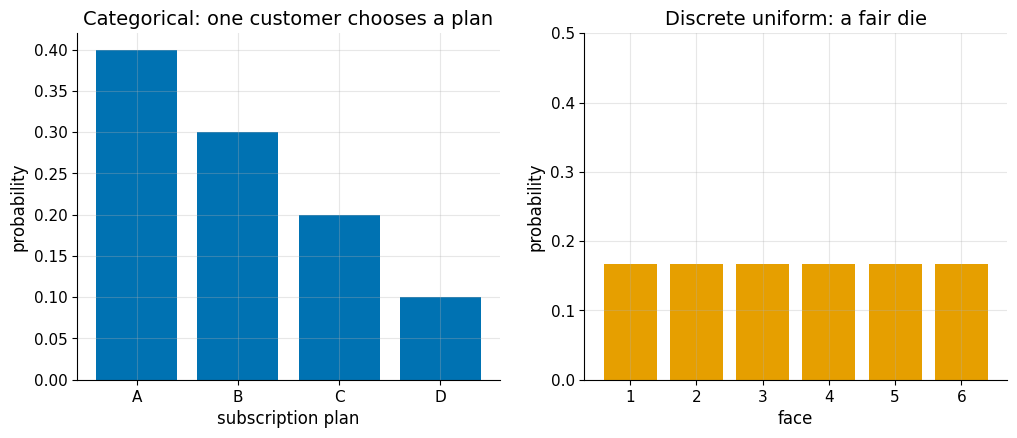

In [2]:
plan_probs = np.array([0.40, 0.30, 0.20, 0.10])
plan_names = ["A", "B", "C", "D"]

fig, (ax_cat, ax_uni) = plt.subplots(1, 2, figsize=(12, 4.5))
ax_cat.bar(plan_names, plan_probs, color=MAIN)
ax_cat.set_title("Categorical: one customer chooses a plan")
ax_cat.set_xlabel("subscription plan")
ax_cat.set_ylabel("probability")

die_faces = np.arange(1, 7)
ax_uni.bar(die_faces, stats.randint(1, 7).pmf(die_faces), color=SIM)
ax_uni.set_title("Discrete uniform: a fair die")
ax_uni.set_xlabel("face")
ax_uni.set_ylabel("probability")
ax_uni.set_ylim(0, 0.5)
plt.show()

### 7.2 Multinomial counts: marginal distributions
For 1,200 customers, the count in each plan is Binomial. The bars show the PMF of each count; the dashed lines mark the means np.

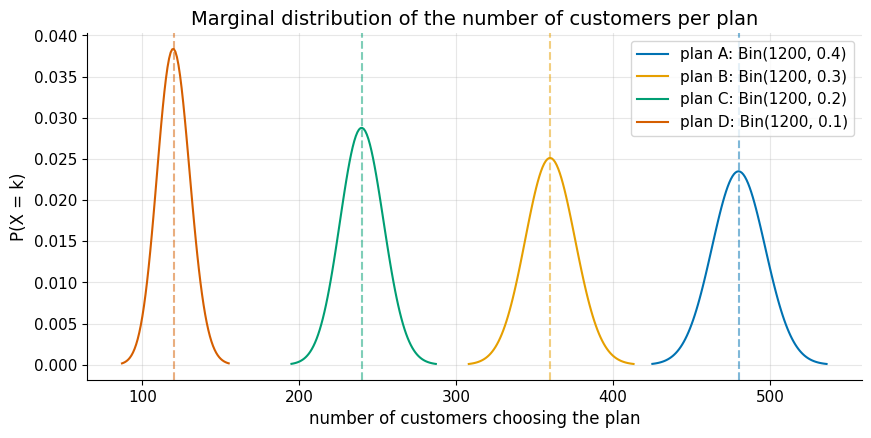

In [3]:
n_customers = 1200
fig, ax = plt.subplots(figsize=(10, 4.5))
for name, p_plan, color in zip(plan_names, plan_probs, COLORS):
    marginal = stats.binom(n_customers, p_plan)
    counts = np.arange(int(marginal.ppf(0.0005)), int(marginal.ppf(0.9995)) + 1)
    ax.plot(counts, marginal.pmf(counts), color=color, label=f"plan {name}: Bin(1200, {p_plan})")
    ax.axvline(n_customers * p_plan, color=color, linestyle="--", alpha=0.5)
ax.set_title("Marginal distribution of the number of customers per plan")
ax.set_xlabel("number of customers choosing the plan")
ax.set_ylabel("P(X = k)")
ax.legend()
plt.show()

### 7.3 Negative dependence between counts
We simulate many multinomial draws and plot count of plan A against count of plan B: a downward-sloping cloud, correlation about $-\sqrt{0.4\cdot0.3/(0.6\cdot0.7)}=-0.53$.

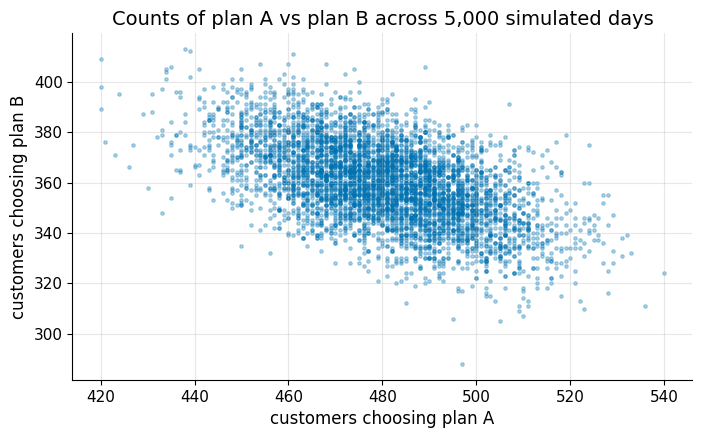

simulated correlation = -0.549, theory = -0.535
simulated covariance = -150.2, theory -n p_a p_b = -144.0


In [4]:
draws = rng.multinomial(n=n_customers, pvals=plan_probs, size=5000)       # shape (5000, 4)
counts_a = draws[:, 0]
counts_b = draws[:, 1]

fig, ax = plt.subplots()
ax.scatter(counts_a, counts_b, s=6, alpha=0.3, color=MAIN)
ax.set_title("Counts of plan A vs plan B across 5,000 simulated days")
ax.set_xlabel("customers choosing plan A")
ax.set_ylabel("customers choosing plan B")
plt.show()

theory_corr = -np.sqrt(0.4 * 0.3 / (0.6 * 0.7))
print(f"simulated correlation = {np.corrcoef(counts_a, counts_b)[0, 1]:.3f}, theory = {theory_corr:.3f}")
print(f"simulated covariance = {np.cov(counts_a, counts_b)[0, 1]:.1f}, theory -n p_a p_b = {-n_customers * 0.4 * 0.3:.1f}")

### 7.4 Softmax turns scores into a Categorical distribution
Larger logits get larger probabilities; the outputs always sum to 1.

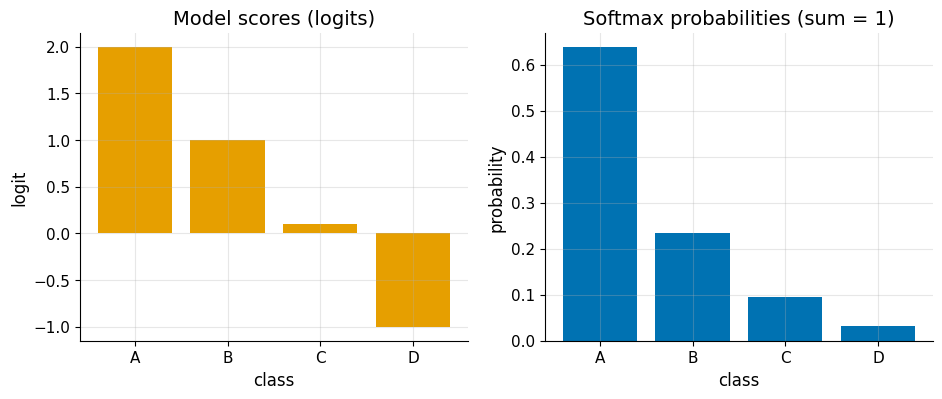

probabilities: [0.638 0.235 0.095 0.032] sum = 1.0


In [5]:
logits = np.array([2.0, 1.0, 0.1, -1.0])
softmax_probs = np.exp(logits) / np.exp(logits).sum()

fig, (ax_logits, ax_probs) = plt.subplots(1, 2, figsize=(11, 4))
ax_logits.bar(plan_names, logits, color=SIM)
ax_logits.set_title("Model scores (logits)")
ax_logits.set_xlabel("class")
ax_logits.set_ylabel("logit")
ax_probs.bar(plan_names, softmax_probs, color=MAIN)
ax_probs.set_title("Softmax probabilities (sum = 1)")
ax_probs.set_xlabel("class")
ax_probs.set_ylabel("probability")
plt.show()
print("probabilities:", softmax_probs.round(3), "sum =", softmax_probs.sum())

## 8. 3D visuals

### 8.1 Static: Multinomial with 3 categories as 3D bars
For n = 10 and probabilities (0.5, 0.3, 0.2), the count of class 3 is determined: x3 = n - x1 - x2. Each bar sits over (x1, x2) and its height is the probability. Only the points with x1 + x2 at most n exist (a triangle).

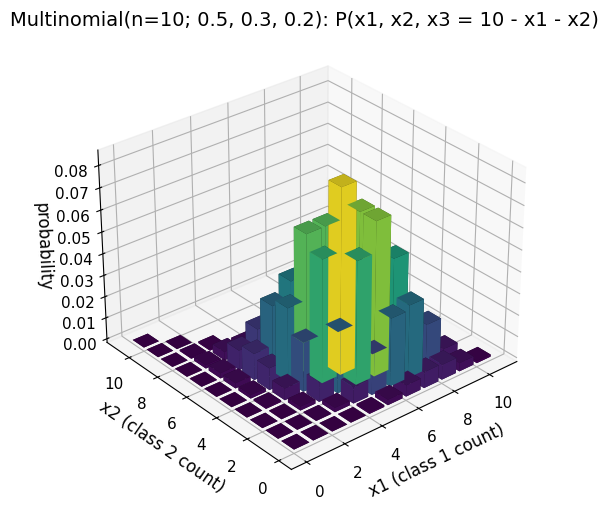

In [6]:
n = 10
probs3 = np.array([0.5, 0.3, 0.2])
x1_list, x2_list, heights = [], [], []
for x1 in range(n + 1):
    for x2 in range(n + 1 - x1):
        x3 = n - x1 - x2
        x1_list.append(x1)
        x2_list.append(x2)
        heights.append(stats.multinomial(n, probs3).pmf([x1, x2, x3]))
x1_array, x2_array, heights = np.array(x1_list), np.array(x2_list), np.array(heights)
assert np.isclose(heights.sum(), 1.0)

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection="3d")
colors = plt.cm.viridis(heights / heights.max())
ax.bar3d(x1_array, x2_array, np.zeros_like(heights), 0.8, 0.8, heights, color=colors)
ax.set_title("Multinomial(n=10; 0.5, 0.3, 0.2): P(x1, x2, x3 = 10 - x1 - x2)")
ax.set_xlabel("x1 (class 1 count)")
ax.set_ylabel("x2 (class 2 count)")
ax.set_zlabel("probability")
ax.view_init(elev=30, azim=-130)
plt.show()

### 8.2 Interactive Plotly version
Markers sit over the simplex points (x1, x2); height and color show the probability. Drag to rotate, hover for the values.

In [7]:
x3_array = n - x1_array - x2_array
fig = go.Figure(go.Scatter3d(
    x=x1_array, y=x2_array, z=heights, mode="markers",
    marker=dict(size=5, color=heights, colorscale="Viridis", showscale=True),
    text=[f"x3 = {v}" for v in x3_array]))
fig.update_layout(title="Multinomial(10; 0.5, 0.3, 0.2) over (x1, x2)", width=750, height=550,
                  scene=dict(xaxis_title="x1", yaxis_title="x2", zaxis_title="probability"))
fig.show()

## 9. Simulation vs theory

### 9.1 Histogram of a count against its Binomial marginal
The count of plan D over 20,000 simulated days against Bin(1200, 0.1).

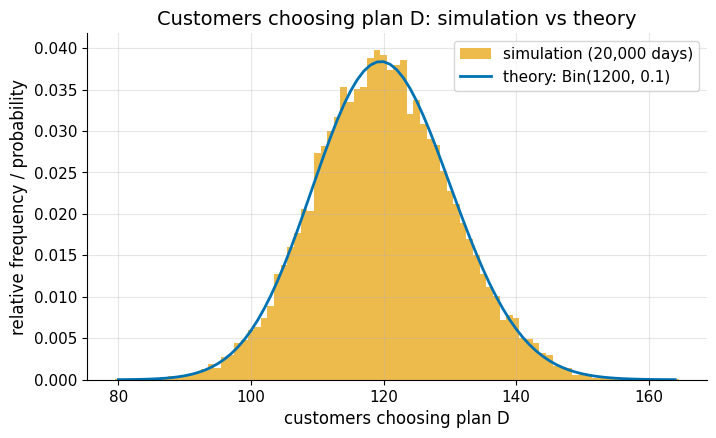

mean of simulated rows: [480.  360.1 239.9 120. ]  theory: [480. 360. 240. 120.]


In [8]:
draws = rng.multinomial(n=n_customers, pvals=plan_probs, size=20_000)
plan_d = draws[:, 3]
theory = stats.binom(n_customers, 0.1)
counts = np.arange(80, 165)

fig, ax = plt.subplots()
ax.hist(plan_d, bins=np.arange(80, 166) - 0.5, density=True, color=SIM, alpha=0.7, label="simulation (20,000 days)")
ax.plot(counts, theory.pmf(counts), color=MAIN, linewidth=2, label="theory: Bin(1200, 0.1)")
ax.set_title("Customers choosing plan D: simulation vs theory")
ax.set_xlabel("customers choosing plan D")
ax.set_ylabel("relative frequency / probability")
ax.legend()
plt.show()
print("mean of simulated rows:", draws.mean(axis=0).round(1), " theory:", n_customers * plan_probs)

### 9.2 Running mean of the plan D count

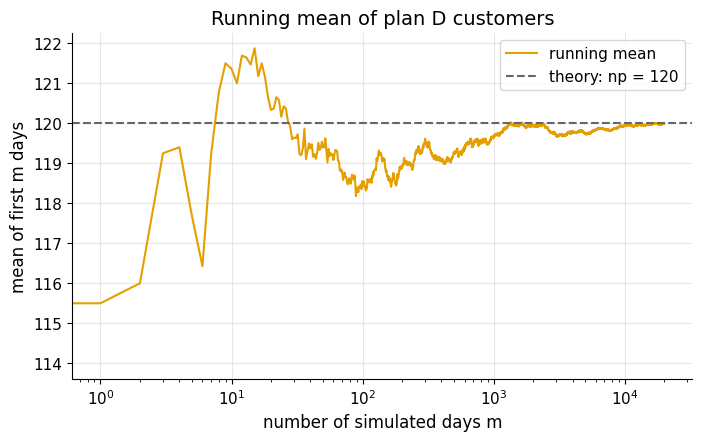

In [9]:
running_mean = np.cumsum(plan_d) / np.arange(1, len(plan_d) + 1)

fig, ax = plt.subplots()
ax.plot(running_mean, color=SIM, label="running mean")
ax.axhline(120, color=NEUTRAL, linestyle="--", label="theory: np = 120")
ax.set_title("Running mean of plan D customers")
ax.set_xlabel("number of simulated days m")
ax.set_ylabel("mean of first m days")
ax.set_xscale("log")
ax.legend()
plt.show()

## 10. `scipy.stats` cheat sheet

`scipy.stats.multinomial` handles the joint PMF; use `binom` for a single count and `randint` for the discrete uniform. There is no separate categorical class: `rng.choice` or `multinomial(1, p)` draws one.

In [10]:
multi = stats.multinomial(n=10, p=[0.5, 0.3, 0.2])
print("pmf([5,3,2])     :", round(multi.pmf([5, 3, 2]), 5))
print("mean             :", multi.mean())
print("cov (singular)   :\n", multi.cov())
print("rvs(3)           :\n", multi.rvs(size=3, random_state=1))

die = stats.randint(low=1, high=7)           # discrete uniform on 1..6 (high is exclusive)
print("randint pmf(3)   :", die.pmf(3), " mean:", die.mean(), " var:", round(die.var(), 4))
print("chisquare        :", stats.chisquare([18, 22, 20], f_exp=[20, 20, 20]))

pmf([5,3,2])     : 0.08505
mean             : [5. 3. 2.]
cov (singular)   :
 [[ 2.5 -1.5 -1. ]
 [-1.5  2.1 -0.6]
 [-1.  -0.6  1.6]]
rvs(3)           :
 [[5 2 3]
 [0 7 3]
 [3 6 1]]
randint pmf(3)   : 0.16666666666666666  mean: 3.5  var: 2.9167
chisquare        : Power_divergenceResult(statistic=np.float64(0.4), pvalue=np.float64(0.8187307530779818))


**Fitting:** the MLE of the category probabilities is the observed proportion of each class, $\hat p_j=x_j/n$.

In [11]:
observed = np.array([450, 380, 240, 130])
print("MLE probabilities:", (observed / observed.sum()).round(4))

MLE probabilities: [0.375  0.3167 0.2    0.1083]


## 11. Real-world worked example: subscription plans

**Scenario (illustrative numbers).** **1,200 customers** each choose one of 4 subscription plans with probabilities **(0.40, 0.30, 0.20, 0.10)**. The counts $(X_A,X_B,X_C,X_D)\sim\text{Mult}(1200;\,0.4,0.3,0.2,0.1)$.

**Questions**
1. What is the expected count per plan?
2. What is $P(X_D\ge150)$?
3. A month later the observed split is **(450, 380, 240, 130)**. Is it consistent with the assumed probabilities?

### 11.1 By hand
**Q1.** $E[X_j]=np_j$: $1200\times0.4=480$, $1200\times0.3=360$, $1200\times0.2=240$, $1200\times0.1=120$.

**Q2.** $X_D\sim\text{Bin}(1200,0.1)$ has mean 120 and variance $1200\times0.1\times0.9=108$, SD $=\sqrt{108}=10.39$. Normal approximation with continuity correction:
$$z=\frac{149.5-120}{10.39}=2.84,\qquad P(X_D\ge150)\approx1-\Phi(2.84)\approx0.0023.$$
The exact tail sum of the Binomial PMF is computed in code.

**Q3.** Chi-square statistic $\chi^2=\sum_j\frac{(O_j-E_j)^2}{E_j}$:
$$\frac{(450-480)^2}{480}+\frac{(380-360)^2}{360}+\frac{(240-240)^2}{240}+\frac{(130-120)^2}{120}=1.875+1.111+0+0.833=3.819.$$
Under the null, $\chi^2\sim\chi^2_{k-1}=\chi^2_3$. The 5 % critical value for 3 degrees of freedom is $7.815$. Since $3.819<7.815$ we do not reject; the p-value is computed in code.

In [12]:
import math

n_customers = 1200
plan_probs = np.array([0.40, 0.30, 0.20, 0.10])
observed = np.array([450, 380, 240, 130])

expected_hand = n_customers * plan_probs
chi_square_hand = 0.0
for observed_count, expected_count in zip(observed, expected_hand):
    chi_square_hand += (observed_count - expected_count) ** 2 / expected_count

# P(X_D >= 150): sum the Binomial PMF formula; terms beyond k = 250 are smaller than 1e-30, so we stop there
# (math.comb of huge numbers times a tiny float would overflow)
p_d_at_least_150_hand = sum(
    math.comb(n_customers, k) * 0.1**k * 0.9**(n_customers - k) for k in range(150, 251))
print("expected:", expected_hand, " chi-square:", round(chi_square_hand, 3), " P(X_D >= 150):", round(p_d_at_least_150_hand, 5))

expected: [480. 360. 240. 120.]  chi-square: 3.819  P(X_D >= 150): 0.00291


### 11.2 In code with `scipy`, and the asserts

In [13]:
plan_d_dist = stats.binom(n=n_customers, p=0.1)
p_d_at_least_150_code = plan_d_dist.sf(149)
chi_square_code, p_value_code = stats.chisquare(f_obs=observed, f_exp=expected_hand)

assert np.isclose(p_d_at_least_150_hand, p_d_at_least_150_code)
assert np.isclose(chi_square_hand, chi_square_code)
print(f"P(X_D >= 150) = {p_d_at_least_150_code:.5f}")
print(f"chi-square = {chi_square_code:.3f}, df = 3, p-value = {p_value_code:.3f}")
print("critical value at 5%:", round(stats.chi2.ppf(0.95, df=3), 3))

P(X_D >= 150) = 0.00291
chi-square = 3.819, df = 3, p-value = 0.282
critical value at 5%: 7.815


### 11.3 Verify by simulation
Simulate 100,000 months of 1,200 customers. Also simulate the chi-square statistic under the null to see where 3.82 falls.

In [14]:
simulated = rng.multinomial(n=n_customers, pvals=plan_probs, size=100_000)
print(f"P(X_D >= 150): exact {p_d_at_least_150_code:.5f}, simulated {np.mean(simulated[:, 3] >= 150):.5f}")

simulated_chi_squares = (((simulated - expected_hand) ** 2) / expected_hand).sum(axis=1)
p_value_simulated = np.mean(simulated_chi_squares >= chi_square_code)
print(f"p-value of the observed split: chi-square table {p_value_code:.3f}, simulation {p_value_simulated:.3f}")
assert abs(p_value_simulated - p_value_code) < 0.01

P(X_D >= 150): exact 0.00291, simulated 0.00265
p-value of the observed split: chi-square table 0.282, simulation 0.282


### 11.4 Plots with the regions shaded

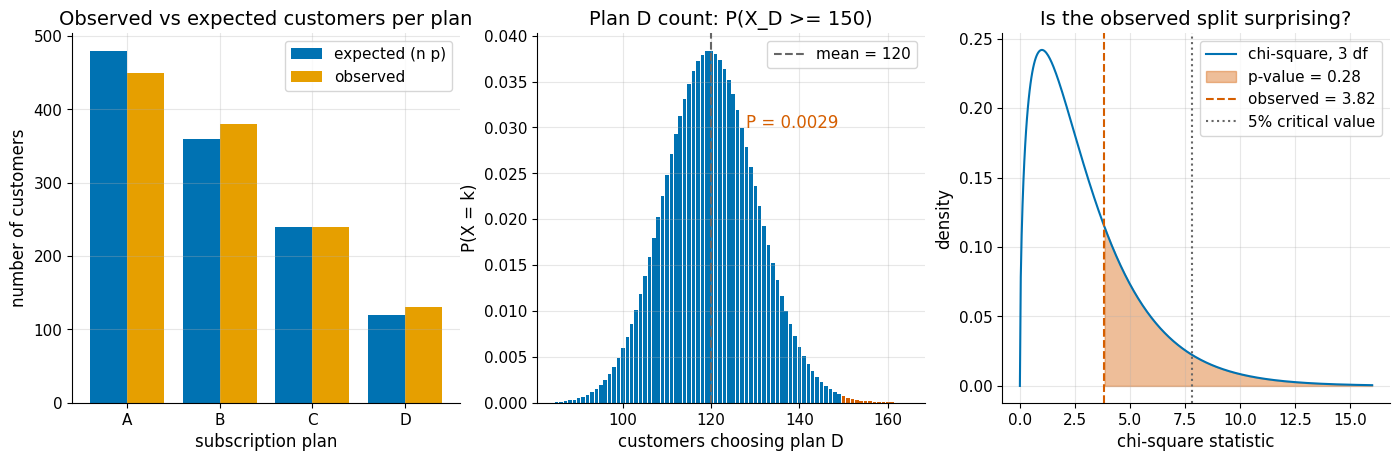

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

# Panel 1: observed vs expected counts
positions = np.arange(4)
width = 0.4
axes[0].bar(positions - width / 2, expected_hand, width=width, color=MAIN, label="expected (n p)")
axes[0].bar(positions + width / 2, observed, width=width, color=SIM, label="observed")
axes[0].set_xticks(positions)
axes[0].set_xticklabels(plan_names)
axes[0].set_title("Observed vs expected customers per plan")
axes[0].set_xlabel("subscription plan")
axes[0].set_ylabel("number of customers")
axes[0].legend()

# Panel 2: P(X_D >= 150)
counts = np.arange(85, 165)
axes[1].bar(counts, plan_d_dist.pmf(counts), color=MAIN)
tail = counts >= 150
axes[1].bar(counts[tail], plan_d_dist.pmf(counts[tail]), color=HIGHLIGHT)
axes[1].axvline(120, color=NEUTRAL, linestyle="--", label="mean = 120")
axes[1].set_title("Plan D count: P(X_D >= 150)")
axes[1].text(128, 0.03, f"P = {p_d_at_least_150_code:.4f}", color=HIGHLIGHT, fontsize=12)
axes[1].set_xlabel("customers choosing plan D")
axes[1].set_ylabel("P(X = k)")
axes[1].legend()

# Panel 3: chi-square null distribution with the observed value
chi_values = np.linspace(0, 16, 400)
axes[2].plot(chi_values, stats.chi2(df=3).pdf(chi_values), color=MAIN, label="chi-square, 3 df")
axes[2].fill_between(chi_values, stats.chi2(df=3).pdf(chi_values), where=chi_values >= chi_square_code, color=HIGHLIGHT, alpha=0.4, label=f"p-value = {p_value_code:.2f}")
axes[2].axvline(chi_square_code, color=HIGHLIGHT, linestyle="--", label=f"observed = {chi_square_code:.2f}")
axes[2].axvline(stats.chi2.ppf(0.95, 3), color=NEUTRAL, linestyle=":", label="5% critical value")
axes[2].set_title("Is the observed split surprising?")
axes[2].set_xlabel("chi-square statistic")
axes[2].set_ylabel("density")
axes[2].legend()
plt.show()

### 11.5 Interpretation and decision
- Expect about **480 / 360 / 240 / 120** customers on plans A / B / C / D.
- It is **very unlikely (about 0.3 %) that plan D reaches 150 customers** if its true share is 10 %. If it does, something has changed.
- The observed split (450, 380, 240, 130) has a p-value of about **0.28**: well within normal random variation. **Decision:** no evidence that customer preferences changed, so keep the current pricing and capacity plan. Plan D is a little above its expected 120 (130), but that gap is about one standard deviation.

### 11.6 Second example: is a die fair?
A die is rolled 600 times (illustrative counts): faces 1 to 6 appear **(88, 109, 107, 94, 105, 97)** times. A fair die has expected count 100 per face.

In [16]:
die_counts = np.array([88, 109, 107, 94, 105, 97])
chi_by_hand = ((die_counts - 100) ** 2 / 100).sum()
chi_code, p_die = stats.chisquare(die_counts, f_exp=[100] * 6)
assert np.isclose(chi_by_hand, chi_code)
print(f"chi-square = {chi_code:.2f} on 5 df, p-value = {p_die:.3f}  -> no evidence the die is unfair")

chi-square = 3.44 on 5 df, p-value = 0.632  -> no evidence the die is unfair


---
### Example 2: is the die fair? (a goodness-of-fit test)

**Scenario (illustrative).** A die is rolled **600 times** with counts for the faces 1 to 6 of **89, 112, 98, 105, 94, 102**. Is it consistent with a fair die?

**Questions**
1. What are the expected counts and the chi-square statistic?
2. What is the p-value? What do you conclude?
3. If the die were really biased with $P(6)=0.20$ and the other faces $0.16$, how often would a test with 600 rolls detect it at the 5 % level?

### 11.6 By hand

**Q1.** Expected $=600/6=100$ per face. $\chi^2=\sum\frac{(O-100)^2}{100}=\frac{121+144+4+25+36+4}{100}=\mathbf{3.34}$ with $6-1=5$ degrees of freedom.

**Q2.** $P(\chi^2_5\ge3.34)=\mathbf{0.65}$: far above 0.05, so there is **no evidence** against a fair die (the 5 % critical value is 11.07).

**Q3.** The power is computed by simulation below (it is about 0.35: a bias of 3 points on one face is detected only about one time in three with 600 rolls).

chi-square = 3.34, p-value = 0.648 (scipy: 3.34, 0.648) | critical value at 5 %: 11.07


fair die rejected in 0.056 of the tests (should be about 0.05) | biased die (P(6) = 0.20) rejected in 0.346 (the power)


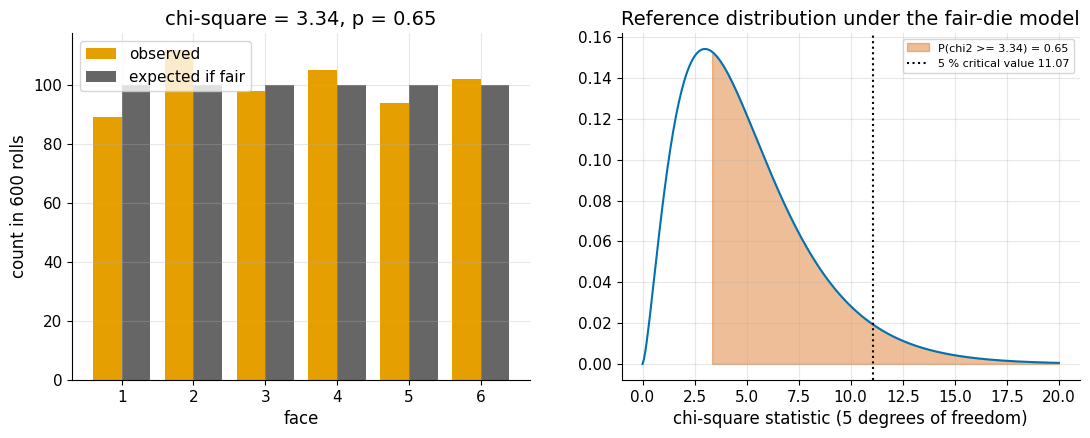

In [17]:
obs_a = np.array([89, 112, 98, 105, 94, 102]); exp_a = np.full(6, 100.0)
chi_a = ((obs_a - exp_a) ** 2 / exp_a).sum(); p_a = stats.chi2(5).sf(chi_a)
res_a = stats.chisquare(obs_a, exp_a)
print(f"chi-square = {chi_a:.2f}, p-value = {p_a:.3f} (scipy: {res_a.statistic:.2f}, {res_a.pvalue:.3f}) | critical value at 5 %: {stats.chi2(5).ppf(0.95):.2f}")
assert np.isclose(chi_a, 3.34) and np.isclose(p_a, res_a.pvalue) and sum(obs_a) == 600
sim_a = np.random.default_rng(3)
rej_fair = np.mean([stats.chisquare(sim_a.multinomial(600, np.full(6, 1 / 6))).pvalue < 0.05 for rep_a in range(4000)])
rej_bias = np.mean([stats.chisquare(sim_a.multinomial(600, [0.16] * 5 + [0.20])).pvalue < 0.05 for rep_a in range(4000)])
print(f"fair die rejected in {rej_fair:.3f} of the tests (should be about 0.05) | biased die (P(6) = 0.20) rejected in {rej_bias:.3f} (the power)")
assert abs(rej_fair - 0.05) < 0.02 and 0.20 < rej_bias < 0.50
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].bar(np.arange(1, 7) - 0.2, obs_a, 0.4, color=SIM, label="observed"); axes[0].bar(np.arange(1, 7) + 0.2, exp_a, 0.4, color=NEUTRAL, label="expected if fair"); axes[0].set_xlabel("face"); axes[0].set_ylabel("count in 600 rolls"); axes[0].set_title(f"chi-square = {chi_a:.2f}, p = {p_a:.2f}"); axes[0].legend()
xs_a = np.linspace(0, 20, 300); axes[1].plot(xs_a, stats.chi2(5).pdf(xs_a), color=MAIN); axes[1].fill_between(xs_a, 0, stats.chi2(5).pdf(xs_a), where=xs_a >= chi_a, color=HIGHLIGHT, alpha=0.4, label=f"P(chi2 >= {chi_a:.2f}) = {p_a:.2f}"); axes[1].axvline(stats.chi2(5).ppf(0.95), color="black", linestyle=":", label="5 % critical value 11.07")
axes[1].set_xlabel("chi-square statistic (5 degrees of freedom)"); axes[1].set_title("Reference distribution under the fair-die model"); axes[1].legend(fontsize=8)
plt.show()

### 11.7 Interpretation and decision (Example 2)

- The counts are close to the expected 100 per face: $\chi^2=3.34$ is well inside the range of ordinary fluctuation, with a **p-value of 0.65**. The data give **no reason to doubt that the die is fair**.
- That is not proof of fairness: a test with 600 rolls would flag a die with $P(6)=0.20$ (instead of 0.167) only about **35 % of the time**, while a truly fair die is wrongly flagged in 5 % of the tests, as designed.
- **Decision.** Accept the die for casual use; for a casino or a game where a 3-point bias matters, roll thousands of times (the power grows with the number of rolls) before certifying it.

---
### Example 3: assigning users to four variants (negative correlation of counts)

**Scenario (illustrative).** **1,000 users** are assigned independently and uniformly to **4 variants** of a page, so the counts $(X_1,\dots,X_4)\sim\text{Mult}(1000;\tfrac14,\tfrac14,\tfrac14,\tfrac14)$.

**Questions**
1. What are the mean and SD of each count?
2. What is the correlation between two counts?
3. What is the probability that at least one variant gets more than **280** users? (An imbalance of this size might bias a comparison.)

### 11.8 By hand

**Q1.** Each $X_i\sim\text{Bin}(1000,\frac14)$: mean $\mathbf{250}$, SD $=\sqrt{1000\cdot\frac14\cdot\frac34}=\mathbf{13.69}$.

**Q2.** $\mathrm{Cov}(X_i,X_j)=-np_ip_j=-1000/16=-62.5$, so the correlation is $-62.5/187.5=\mathbf{-1/3}$: when one variant gets more users, the others get fewer.

**Q3.** For one variant, $P(X_1>280)=P(Z>\frac{280.5-250}{13.69})=P(Z>2.23)\approx0.0137$; two variants can hardly both exceed 280, so $P(\max>280)\approx4\times0.0137=\mathbf{0.055}$.

each count: mean 250, SD 13.69 | covariance -62.5, correlation -0.333 | P(one variant > 280) = 0.0137, union bound 0.0549
simulation: SD 13.72, correlation of two counts -0.335, P(max count > 280) = 0.0553


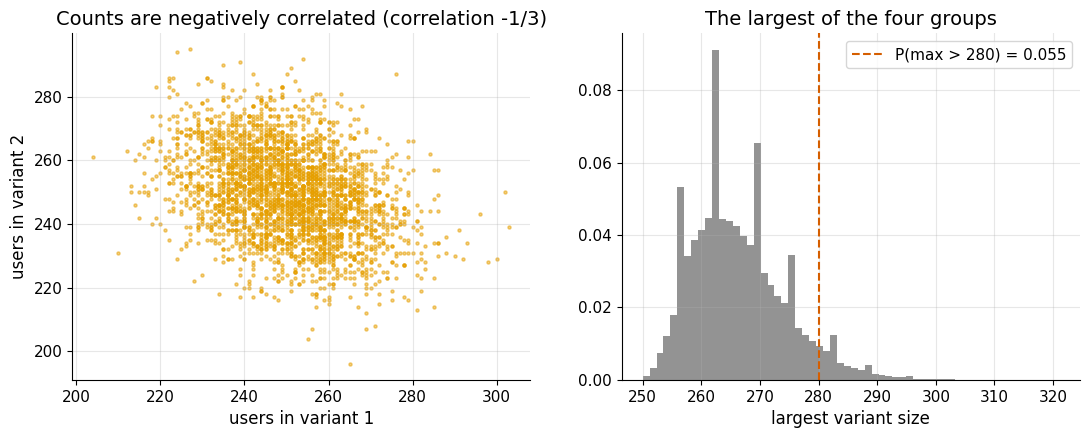

In [18]:
n_b, k_b = 1000, 4
p_one = stats.binom(n_b, 1 / k_b).sf(280); union_b = k_b * p_one
cov_b = -n_b * (1 / k_b) ** 2; corr_b = cov_b / (n_b * (1 / k_b) * (1 - 1 / k_b))
sim_b = np.random.default_rng(14).multinomial(n_b, [1 / k_b] * k_b, size=400_000)
print(f"each count: mean {n_b / k_b:.0f}, SD {np.sqrt(n_b * 0.25 * 0.75):.2f} | covariance {cov_b:.1f}, correlation {corr_b:.3f} | P(one variant > 280) = {p_one:.4f}, union bound {union_b:.4f}")
print(f"simulation: SD {sim_b[:, 0].std():.2f}, correlation of two counts {np.corrcoef(sim_b[:, 0], sim_b[:, 1])[0, 1]:.3f}, P(max count > 280) = {np.mean(sim_b.max(axis=1) > 280):.4f}")
assert np.isclose(corr_b, -1 / 3) and abs(np.corrcoef(sim_b[:, 0], sim_b[:, 1])[0, 1] + 1 / 3) < 0.005 and np.mean(sim_b.max(axis=1) > 280) <= union_b + 1e-3
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(sim_b[:3000, 0], sim_b[:3000, 1], s=5, color=SIM, alpha=0.5); axes[0].set_xlabel("users in variant 1"); axes[0].set_ylabel("users in variant 2"); axes[0].set_title("Counts are negatively correlated (correlation -1/3)")
axes[1].hist(sim_b.max(axis=1), bins=60, color=NEUTRAL, alpha=0.7, density=True); axes[1].axvline(280, color=HIGHLIGHT, linestyle="--", label=f"P(max > 280) = {np.mean(sim_b.max(axis=1) > 280):.3f}"); axes[1].set_xlabel("largest variant size"); axes[1].set_title("The largest of the four groups"); axes[1].legend()
plt.show()

### 11.9 Interpretation and decision (Example 3)

- Every group has about **250 users** give or take 14 (a 5.5 % relative fluctuation); the groups are **negatively correlated** (-1/3) because the four counts must add to 1,000.
- The chance that **at least one variant exceeds 280 users** is about **5.5 %** in the simulation, equal to the union bound over four variants (4 x 1.37 %) because two groups can hardly be oversized together: roughly one test in eighteen has a visibly oversized group by chance.
- **Decision.** If equal group sizes matter (for example for a power calculation) use **blocked or stratified randomisation** that guarantees equal counts, instead of independent assignment; otherwise accept small imbalances and analyse with the actual group sizes.

## 12. Where it is used

### Statistics
- **Chi-square goodness of fit and homogeneity tests** for categorical data; contingency tables.
- **Survey analysis:** the number of respondents choosing each option is Multinomial; confidence intervals for shares.
- **Multinomial logistic regression** models a categorical response.

### Data science
- **Category share monitoring:** product mix, traffic sources, plan choices over time.
- **Label distribution checks** for classification datasets (class imbalance, data drift).

### ML and AI
- **Classifier outputs:** softmax gives a Categorical distribution; the **cross-entropy loss** is the negative log-likelihood of the true one-hot label.
- **Bag-of-words and Naive Bayes:** a document's word counts are modelled as Multinomial.
- **LLM next-token sampling (preview):** the next token is a draw from a Categorical over the vocabulary, shaped by temperature.

## 13. Common pitfalls and misconceptions

- **Counts are not independent:** they sum to n and are negatively correlated. Treating each category as an independent Binomial for joint statements is wrong.
- **Chi-square needs enough data:** expected counts should be at least about 5 in every category; merge sparse categories.
- **Degrees of freedom:** k - 1 for given probabilities; subtract one more for each parameter estimated from the data.
- **A large p-value is not proof of fairness:** it only says the data are consistent with the model.
- **`randint` high is exclusive:** `stats.randint(1, 7)` covers 1 to 6.
- **Probabilities must sum to 1:** normalize before sampling (softmax does this automatically).

## 14. Exercises

1. A fair die is rolled once. State the distribution, its mean and variance.
2. A bag has 50 % red, 30 % green, 20 % blue marbles (drawn with replacement). Find the probability that 10 draws give exactly 5 red, 3 green and 2 blue.
3. For the plans in section 11, find $\mathrm{Cov}(X_A,X_B)$ and the correlation between $X_A$ and $X_B$.
4. Convert the logits $(1,2,3)$ to probabilities with softmax, then compute the cross-entropy loss if the true class is the second one.
5. 300 users are split among 3 landing pages. Observed (90, 120, 90). Test whether the pages are equally popular.
6. Simulate 5,000 multinomial draws with $n=100$, $p=(0.2,0.5,0.3)$ and verify numerically that the sample covariance matrix is close to $n(\mathrm{diag}(p)-pp^\top)$.
7. (Harder) Show that $X_1+X_2$ is Binomial($n,p_1+p_2$) for a Multinomial.
8. (Harder) Show that $\mathrm{Var}(X_1+X_2+X_3)=0$ for a 3-class Multinomial, using the covariance formulas.

9. A fair die is rolled 6 times. What is the probability that every face appears exactly once? Compute it with the Multinomial formula and check by simulation.
10. For a discrete Uniform on $\{1,\dots,10\}$ find the mean, variance and $P(X\le3)$. For which $N$ does the variance equal 20?
11. In the subscription example of Example 1 (1,200 customers; probabilities 0.4, 0.3, 0.2, 0.1) find the covariance and correlation of the counts for plans A and B.

Solutions are at the end.

## 15. Summary table

| Item | Discrete uniform | Categorical | Multinomial |
|---|---|---|---|
| Parameters | a, b | p_1..p_k | n, p_1..p_k |
| Support | a..b | classes 1..k | counts summing to n |
| Mean | (a+b)/2 | p_j (one-hot) | n p_j |
| Variance | ((b-a+1)^2 - 1)/12 | p_j (1-p_j) | n p_j (1-p_j) |
| Covariance | | | -n p_i p_j |
| When to use | equally likely outcomes | one draw from k classes | counts over k classes in n draws |
| `scipy` name | `stats.randint(a, b+1)` | `rng.choice`, `multinomial(1, p)` | `stats.multinomial(n, p)` |

## Solutions

In [19]:
print("1: mean", stats.randint(1, 7).mean(), " var", stats.randint(1, 7).var())
print("2:", stats.multinomial(10, [0.5, 0.3, 0.2]).pmf([5, 3, 2]))
cov_ab = -1200 * 0.4 * 0.3
corr_ab = cov_ab / np.sqrt(1200 * 0.4 * 0.6 * 1200 * 0.3 * 0.7)
print("3: cov", cov_ab, " corr", round(corr_ab, 4))

z = np.array([1.0, 2.0, 3.0])
soft = np.exp(z) / np.exp(z).sum()
print("4: softmax", soft.round(4), " loss", -np.log(soft[1]))
print("5:", stats.chisquare([90, 120, 90], f_exp=[100, 100, 100]))

p6 = np.array([0.2, 0.5, 0.3])
samples = rng.multinomial(100, p6, size=5000)
print("6: sample cov\n", np.cov(samples.T).round(2), "\n theory\n", (100 * (np.diag(p6) - np.outer(p6, p6))).round(2))

1: mean 3.5  var 2.9166666666666665
2: 0.08504999999999999
3: cov -144.0  corr -0.5345
4: softmax [0.09   0.2447 0.6652]  loss 1.4076059644443801
5: Power_divergenceResult(statistic=np.float64(6.0), pvalue=np.float64(0.04978706836786395))
6: sample cov
 [[ 15.57  -9.88  -5.69]
 [ -9.88  24.63 -14.75]
 [ -5.69 -14.75  20.44]] 
 theory
 [[ 16. -10.  -6.]
 [-10.  25. -15.]
 [ -6. -15.  21.]]


**1.** Discrete uniform on 1..6: mean 3.5, variance $35/12\approx2.917$.

**2.** About 0.0850 (printed above).

**3.** $\mathrm{Cov}=-1200\times0.4\times0.3=-144$; correlation about $-0.53$.

**4.** Softmax of (1, 2, 3) is about (0.090, 0.245, 0.665); the loss is $-\ln0.245\approx1.41$.

**5.** $\chi^2=(100+400+100)/100=6.0$ on 2 df, p-value about 0.0498: borderline; the pages are probably not equally popular, but the evidence is weak.

**6.** The sample covariance matrix matches $n(\mathrm{diag}(p)-pp^\top)$ closely.

**7.** Merge classes 1 and 2 into "class 1 or 2" with probability $p_1+p_2$. Each draw falls in it independently, so the count is Binomial($n,p_1+p_2$).

**8.** The three counts sum to the constant $n$, whose variance is 0. Using the formulas: $\sum_i np_i(1-p_i)+2\sum_{i<j}(-np_ip_j)=n\big[\sum p_i-\sum p_i^2-\big((\sum p_i)^2-\sum p_i^2\big)\big]=n[1-1]=0$.

### Solutions to the additional exercises

Each answer is computed below and checked.

In [20]:
pm6 = stats.multinomial(6, [1 / 6] * 6).pmf([1] * 6)
sim6 = np.random.default_rng(8).multinomial(6, [1 / 6] * 6, 600_000); hit6 = np.mean((sim6 == 1).all(axis=1))
print(f"6: P(each face once) = 6!/6^6 = {math.factorial(6) / 6**6:.5f} = {pm6:.5f} | simulated {hit6:.5f}")
u7 = stats.randint(1, 11); n_var20 = int(np.sqrt(12 * 20 + 1))
print(f"7: mean {u7.mean():.2f}, variance {u7.var():.2f} (= (N^2 - 1) / 12 = {(100 - 1) / 12:.2f}), P(X <= 3) = {u7.cdf(3):.2f} | variance 20 needs N^2 = 241, N = {np.sqrt(241):.2f} (no integer N gives exactly 20)")
cov8 = -1200 * 0.4 * 0.3; corr8 = cov8 / np.sqrt(1200 * 0.4 * 0.6 * 1200 * 0.3 * 0.7)
print(f"8: Cov(X_A, X_B) = {cov8:.0f}, correlation = {corr8:.3f} (= -sqrt(pA pB / ((1 - pA)(1 - pB))) = {-np.sqrt(0.4 * 0.3 / (0.6 * 0.7)):.3f})")
assert np.isclose(pm6, 6 * 5 * 4 * 3 * 2 / 6**6) and abs(hit6 - pm6) < 0.0008 and np.isclose(u7.var(), 8.25) and np.isclose(corr8, -np.sqrt(0.4 * 0.3 / (0.6 * 0.7)))

6: P(each face once) = 6!/6^6 = 0.01543 = 0.01543 | simulated 0.01566
7: mean 5.50, variance 8.25 (= (N^2 - 1) / 12 = 8.25), P(X <= 3) = 0.30 | variance 20 needs N^2 = 241, N = 15.52 (no integer N gives exactly 20)
8: Cov(X_A, X_B) = -144, correlation = -0.535 (= -sqrt(pA pB / ((1 - pA)(1 - pB))) = -0.535)
